# cosetsampling: every function, with its output

The R package **cosetsampling** (version 0.1.0) accompanies the paper *Exactly balanced sampling on overlapping
stratifications with affine flats* (M. Laib). It builds **coset designs**: random unions of parallel affine flats
that are exactly balanced on several overlapping stratifications at once, with closed-form first- and
second-order inclusion probabilities and exact variances.

This notebook calls each of the 35 exported functions, and the two print methods, on small examples, most of
them taken from the paper, and shows their output. It was executed with the R kernel IRkernel. The last cell
reads the notebook and checks that every exported function is called.

| Section | Functions |
|---|---|
| [1. Frames](#frames) | `coset_frame()`, `grid_frame()`, `factorial_frame()` |
| [2. Linear algebra over GF(p)](#algebra) | `rref_mod()`, `rank_mod()`, `nullspace_mod()`, `gaussian_binomial()` |
| [3. Stratifications](#strata) | `strata_linear()`, `strata_margins()`, `strata_grid()`, `stratum_labels()`, `main_effect_set()`, `main_effect_count()` |
| [4. Admissible directions](#directions) | `admissible_directions()`, `is_admissible()`, `sample_direction()`, `admissible_exists()` |
| [5. Coset designs and samples](#designs) | `coset_design()`, `draw_sample()`, `inclusion_probabilities()`, `joint_inclusion()` |
| [6. Exact variances](#variance) | `spectral_weights()`, `fourier_power()`, `design_variance()`, `srs_variance()`, `design_effect()`, `worst_case_factor()`, `is_equal_weight()` |
| [7. Minimax mixtures](#minimax) | `minimax_mixture()` |
| [8. Variance estimation](#estimation) | `random_group_variance()`, `regression_variance()` |
| [9. Evaluating any design](#diagnostics) | `balance_check()`, `main_effect_weight()`, `main_effect_share()`, `worst_case_bound()` |
| [10. Coverage check](#coverage) | all exports |

In [1]:
library(cosetsampling)
packageVersion("cosetsampling")
options(jupyter.rich_display = FALSE,   # print results as the R console does
        repr.plot.width = 7, repr.plot.height = 5.5, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")
set.seed(2026)

[1] ‘0.1.0’

<a id="frames"></a>
## 1. Frames

A **coset frame** has $N = q^m$ units, one for each vector $x$ of $\mathrm{GF}(q)^m$, with $q$ prime. Units are
numbered $1, \dots, N$ in the order of the code $\sum_j x_j q^{m-j}$, so the last coordinate varies fastest.
Printing a frame calls the method `print.coset_frame()`.

In [2]:
f <- coset_frame(3, 2)   # 9 units: GF(3)^2
f
f$X                      # coordinates of the units, one row per unit

Coset frame: GF(3)^2, N = 9 units

      [,1] [,2]
 [1,] 0    0   
 [2,] 0    1   
 [3,] 0    2   
 [4,] 1    0   
 [5,] 1    1   
 [6,] 1    2   
 [7,] 2    0   
 [8,] 2    1   
 [9,] 2    2   

`grid_frame(q)` is the $q \times q$ grid as $\mathrm{GF}(q)^2$: unit $(i, j)$, in row $i$ and column $j$, is unit
number $qi + j + 1$.

In [3]:
g7 <- grid_frame(7)
g7
g7$X[c(1, 2, 8, 49), ]   # units (0,0), (0,1), (1,0) and (6,6)

Coset frame: GF(7)^2, N = 49 units

     [,1] [,2]
[1,] 0    0   
[2,] 0    1   
[3,] 1    0   
[4,] 6    6   

`factorial_frame()` maps a complete factorial population, one row per combination of the categories of $m$
variables with $q$ categories each, to the frame. Here there are three binary variables, with the rows in
arbitrary order. Categories are coded in alphabetical order.

In [4]:
pop <- expand.grid(sex = c("F", "M"), region = c("north", "south"),
                   age = c("old", "young"))
pop <- pop[sample(nrow(pop)), ]
ff <- factorial_frame(pop)
ff$frame
data.frame(pop, unit = ff$unit, row.names = NULL)
ff$levels

Coset frame: GF(2)^3, N = 8 units

  sex region age   unit
1 F   north  young 2   
2 F   north  old   1   
3 F   south  young 4   
4 M   south  young 8   
5 F   south  old   3   
6 M   south  old   7   
7 M   north  old   5   
8 M   north  young 6   

$sex
[1] "F" "M"

$region
[1] "north" "south"

$age
[1] "old"   "young"


<a id="algebra"></a>
## 2. Linear algebra over GF(p)

The package does exact linear algebra modulo a prime: reduced row echelon form, rank and null space. It also
gives the Gaussian binomial coefficient, the number of subspaces of a given dimension.

In [5]:
A <- matrix(c(1, 2, 0, 1,
              2, 1, 1, 0,
              0, 0, 1, 2), nrow = 3, byrow = TRUE)
# nonzero rows of the reduced row echelon form over GF(3), and the pivot columns
rref_mod(A, 3)
rank_mod(A, 3)

$R
     [,1] [,2] [,3] [,4]
[1,]    1    2    0    0
[2,]    0    0    1    0
[3,]    0    0    0    1

$pivots
[1] 1 3 4


[1] 3

In [6]:
B <- matrix(c(1, 2, 2, 4), 2)   # over GF(5) the second column is twice the first
rref_mod(B, 5)
rank_mod(B, 5)

$R
     [,1] [,2]
[1,]    1    2

$pivots
[1] 1


[1] 1

In [7]:
K <- nullspace_mod(A, 3)   # basis of {x : A x = 0 (mod 3)}
K
(A %*% t(K)) %% 3          # every basis vector solves the system

     [,1] [,2] [,3] [,4]
[1,] 1    1    0    0   

     [,1]
[1,] 0   
[2,] 0   
[3,] 0   

In [8]:
gaussian_binomial(7, 5, 2)   # 5-dimensional subspaces of GF(2)^7
# subspaces of GF(3)^4, by dimension
setNames(sapply(0:4, function(k) gaussian_binomial(4, k, 3)), 0:4)

[1] 2667

  0   1   2   3   4 
  1  40 130  40   1 

<a id="strata"></a>
## 3. Stratifications

A stratification is given by a subspace $W$: its strata are the cosets $a + W$. It is stored as a basis of
$W^\perp$, the linear forms that are constant on each stratum, so the stratum of unit $x$ is $W^\perp x$.

On a grid, `strata_grid()` gives the wrapped line families: rows ($i$ constant), columns ($j$ constant),
anti-diagonals ($i + j$ constant) and diagonals ($i - j$ constant). Each family is one linear form $(a, b)$, and
the stratum of $(i, j)$ is $ai + bj \bmod q$.

In [9]:
S_grid <- strata_grid(g7, c("rows", "columns", "antidiagonals", "diagonals"))
class(S_grid)
t(sapply(S_grid, c))   # the linear form of each stratification

[1] "coset_strata"

              [,1] [,2]
rows          1    0   
columns       0    1   
antidiagonals 1    1   
diagonals     1    6   

`stratum_labels()` gives the stratum of every unit. On the $7 \times 7$ grid, the anti-diagonal and diagonal
labels show the wrapping.

In [10]:
matrix(stratum_labels(g7, S_grid$antidiagonals), 7, 7, byrow = TRUE)   # i + j mod 7
matrix(stratum_labels(g7, S_grid$diagonals), 7, 7, byrow = TRUE)       # i - j mod 7

     [,1] [,2] [,3] [,4] [,5] [,6] [,7]
[1,] 0    1    2    3    4    5    6   
[2,] 1    2    3    4    5    6    0   
[3,] 2    3    4    5    6    0    1   
[4,] 3    4    5    6    0    1    2   
[5,] 4    5    6    0    1    2    3   
[6,] 5    6    0    1    2    3    4   
[7,] 6    0    1    2    3    4    5   

     [,1] [,2] [,3] [,4] [,5] [,6] [,7]
[1,] 0    6    5    4    3    2    1   
[2,] 1    0    6    5    4    3    2   
[3,] 2    1    0    6    5    4    3   
[4,] 3    2    1    0    6    5    4   
[5,] 4    3    2    1    0    6    5   
[6,] 5    4    3    2    1    0    6   
[7,] 6    5    4    3    2    1    0   

In a complete factorial frame, `strata_margins()` gives the one-variable margins (`order = 1`), or adds all the
two-variable cross-classifications (`order = 2`). A cross-classification has two linear forms.

In [11]:
f27 <- coset_frame(2, 7)                # complete factorial frame 2^7, N = 128
S1 <- strata_margins(f27)               # the 7 one-variable margins
S2 <- strata_margins(f27, order = 2)    # and the 21 two-variable cross-classifications
c(one_variable = length(S1), with_two_variable = length(S2))
S2[[8]]                                 # the cross-classification of variables 1 and 2

     one_variable with_two_variable 
                7                28 

     [,1] [,2] [,3] [,4] [,5] [,6] [,7]
[1,] 1    0    0    0    0    0    0   
[2,] 0    1    0    0    0    0    0   

`strata_linear()` takes any linear forms. In $2^3$, for example, the parity $x_1 + x_2 + x_3 \bmod 2$ is a
stratification that is not a margin.

In [12]:
f23 <- coset_frame(2, 3)
S_par <- strata_linear(f23, list(diag(3)[1, , drop = FALSE], matrix(c(1, 1, 1), 1)))
data.frame(unit = apply(f23$X, 1, paste, collapse = ""),
           variable_1 = stratum_labels(f23, S_par[[1]]),
           parity = stratum_labels(f23, S_par[[2]]))

  unit variable_1 parity
1 000  0          0     
2 001  0          1     
3 010  0          1     
4 011  0          0     
5 100  1          1     
6 101  1          0     
7 110  1          0     
8 111  1          1     

The **main-effect frequencies** $M_{\mathcal S}$ are the nonzero vectors of $\bigcup_W W^\perp$. They carry the
part of a response explained by the main-effects model of the stratifications. The other nonzero vectors are the
residual frequencies $R_{\mathcal S}$. `main_effect_set()` marks $M_{\mathcal S}$ in unit order, and
`main_effect_count()` gives $d_{\mathcal S} = |M_{\mathcal S}|$ and $|R_{\mathcal S}|$.

In [13]:
which(main_effect_set(f23, strata_margins(f23))) - 1   # codes of e3, e2, e1 in 2^3
main_effect_count(g7, S_grid)   # 4 x 6 main-effect frequencies on the 7 x 7 grid
main_effect_count(f27, S1)
main_effect_count(f27, S2)

[1] 1 2 4

       d residual 
      24       24 

       d residual 
       7      120 

       d residual 
      28       99 

<a id="directions"></a>
## 4. Admissible directions

A flat $a + V$ of dimension $h$ has $q^h$ units. It is balanced on $W$ exactly when $V + W$ is the whole space
(Proposition 1 of the paper), that is when $V^\perp \cap W^\perp = \{0\}$. A direction is **admissible** when it is
transversal to every stratification. Directions are stored as a basis $D$ of $V^\perp$, with $m - h$ rows.

For $2^7$ balanced on all seven variables, there are 364 admissible directions of flats of 4 units (Table 1 of the
paper).

In [14]:
dirs <- admissible_directions(f27, S1, h = 2)
length(dirs)
dirs[[1]]   # one dual direction: 5 linear forms

[1] 364

     [,1] [,2] [,3] [,4] [,5] [,6] [,7]
[1,] 1    0    0    0    0    0    1   
[2,] 0    1    0    0    0    0    1   
[3,] 0    0    1    0    0    0    1   
[4,] 0    0    0    1    0    0    1   
[5,] 0    0    0    0    1    0    1   

In [15]:
is_admissible(f27, S1, dirs[[1]])
# D_bad contains the form x1, so its flats are constant on variable 1
D_bad <- rbind(diag(7)[1, ], dirs[[1]][1:4, ])
is_admissible(f27, S1, D_bad)

[1] TRUE

[1] FALSE

`sample_direction()` draws a uniform admissible direction by rejection, without listing them. This is for frames
where listing is too costly, such as the $61 \times 61$ elevation grid of the paper, balanced on rows, columns and
both wrapped diagonals.

In [16]:
g61 <- grid_frame(61)
S4 <- strata_grid(g61, c("rows", "columns", "antidiagonals", "diagonals"))
# the dual form of a random line direction, other than the four balanced ones
sample_direction(g61, S4, h = 1)

     [,1] [,2]
[1,] 1    52  

`admissible_exists()` first checks the sufficient condition of Theorem 1(b): fewer projective points in
$M_{\mathcal S}$ than in a projective space of dimension $h$. Otherwise it enumerates, when that is feasible. The
attribute `reason` says which way the answer was found. The last example takes all eight line families of the
$7 \times 7$ grid, so no line can be balanced on all of them.

In [17]:
# 7 projective points, fewer than the 15 of PG(3, 2): Theorem 1(b)
admissible_exists(f27, S1, h = 3)
# 7 points, not fewer than the 7 of PG(2, 2): decided by enumeration
admissible_exists(f27, S1, h = 2)
# flats of 8 units balanced on all two-variable margins
admissible_exists(f27, S2, h = 3)
S_all <- strata_grid(g7, c("rows", "columns"), slopes = 1:6)
admissible_exists(g7, S_all, h = 1)

[1] TRUE
attr(,"reason")
[1] "sufficient condition of Theorem 1(b)"

[1] TRUE
attr(,"reason")
[1] "enumeration"

[1] TRUE
attr(,"reason")
[1] "enumeration"

[1] FALSE
attr(,"reason")
[1] "enumeration"

<a id="designs"></a>
## 5. Coset designs and samples

The coset design $C(h, \nu, r)$ draws a direction $V$ from the mixing distribution $\nu$. It then selects $r$ of
the $Q = q^{m-h}$ cosets of $V$ by simple random sampling and returns their union. Every sample has
$k = rq^h$ units and is exactly balanced. Printing a design calls `print.coset_design()`.

On the elevation grid, lines in any of the $62 - 4 = 58$ other directions meet every row, column and diagonal once.
With $\nu$ uniform over these directions, the design is an **equal-weight design**.

In [18]:
d61 <- coset_design(g61, S4, h = 1)            # single lines: 61 units
d61
d61x3 <- coset_design(g61, S4, h = 1, r = 3)   # unions of 3 parallel lines: 183 units
d61x3

Coset design C(h = 1, nu, r = 1) on GF(61)^2: N = 3721, sample size k = 61, 4 stratifications
nu: 58 direction(s)

Coset design C(h = 1, nu, r = 3) on GF(61)^2: N = 3721, sample size k = 183, 4 stratifications
nu: 58 direction(s)

In [19]:
s <- draw_sample(d61x3)
str(s)
# every row, column and diagonal holds exactly 3 units
balance_check(g61, S4, s$units)$exact

List of 4
 $ units     : int [1:183] 2 8 50 67 80 86 145 158 164 223 ...
 $ D         : num [1, 1:2] 1 43
 $ cosets    : num [1:3] 43 57 33
 $ unit_coset: num [1:183] 43 57 33 33 43 57 33 43 57 33 ...


[1] TRUE

Here is the sample on the elevation data (rows 14 to 74 of `volcano`), with one colour per line. A line
of the grid wraps around the edges. Unless its slope is small, it therefore looks like a lattice rather than a
straight line.

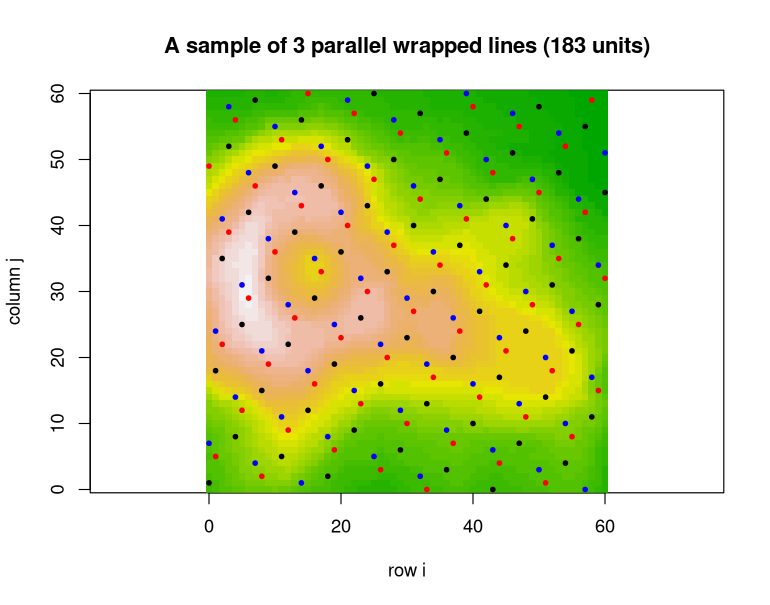

In [20]:
y <- as.vector(t(volcano[14:74, ]))   # elevations of the 61 x 61 block, in unit order
ij <- g61$X[s$units, ]
line_colour <- c("black", "blue", "red")[match(s$unit_coset, s$cosets)]
image(0:60, 0:60, matrix(y, 61, 61, byrow = TRUE), col = terrain.colors(40), asp = 1,
      xlab = "row i", ylab = "column j",
      main = "A sample of 3 parallel wrapped lines (183 units)")
points(ij[, 1], ij[, 2], pch = 19, cex = 0.55, col = line_colour)

The mixing distribution can also be user-given, with probabilities `probs`. It can also be `"rejection"`:
directions are then drawn by rejection when sampling, without being listed. The last example draws flats of 16
units of $2^7$ balanced on all 28 one- and two-variable margins.

In [21]:
S_rc <- strata_grid(g7, c("rows", "columns"))
d_mix <- coset_design(g7, S_rc, h = 1,
                      nu = list(matrix(c(6, 1), 1), matrix(c(5, 1), 1)), probs = c(0.7, 0.3))
d_mix
d_rej <- coset_design(f27, S2, h = 4, nu = "rejection")
d_rej
s_rej <- draw_sample(d_rej)
length(s_rej$units)
balance_check(f27, S2, s_rej$units)$exact

Coset design C(h = 1, nu, r = 1) on GF(7)^2: N = 49, sample size k = 7, 2 stratifications
nu: 2 direction(s)

Coset design C(h = 4, nu, r = 1) on GF(2)^7: N = 128, sample size k = 16, 28 stratifications
nu: uniform over admissible directions, drawn by rejection

[1] 16

[1] TRUE

Every coset design has first-order inclusion probabilities $k/N$. The second-order inclusion probability of
two units depends only on their difference $z$. `joint_inclusion()` returns it for every $z$, or as the
$N \times N$ matrix. Here are the half-samples of $2^3$ balanced on its three variables.

In [22]:
d23 <- coset_design(f23, strata_margins(f23), h = 2)
d23
inclusion_probabilities(d23)
# pi(z) for each difference z, in unit order; the first entry (z = 0) is k/N
joint_inclusion(d23)

Coset design C(h = 2, nu, r = 1) on GF(2)^3: N = 8, sample size k = 4, 3 stratifications
nu: 4 direction(s)

[1] 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5

[1] 0.500 0.125 0.125 0.250 0.125 0.250 0.250 0.375

In [23]:
P <- joint_inclusion(d23, matrix = TRUE)
dimnames(P) <- rep(list(apply(f23$X, 1, paste, collapse = "")), 2)
P

    000   001   010   011   100   101   110   111  
000 0.500 0.125 0.125 0.250 0.125 0.250 0.250 0.375
001 0.125 0.500 0.250 0.125 0.250 0.125 0.375 0.250
010 0.125 0.250 0.500 0.125 0.250 0.375 0.125 0.250
011 0.250 0.125 0.125 0.500 0.375 0.250 0.250 0.125
100 0.125 0.250 0.250 0.375 0.500 0.125 0.125 0.250
101 0.250 0.125 0.375 0.250 0.125 0.500 0.250 0.125
110 0.250 0.375 0.125 0.250 0.125 0.250 0.500 0.125
111 0.375 0.250 0.250 0.125 0.250 0.125 0.125 0.500

<a id="variance"></a>
## 6. Exact variances

Under a translation-invariant design, the variance of the sample mean is $\sum_{u \ne 0} w(u)\,|\hat y(u)|^2$,
where $w$ are the **spectral weights** and $|\hat y(u)|^2$ is the Fourier power of the response. The weights sum
to $N/k - 1$. An exactly balanced design puts no weight on $M_{\mathcal S}$, and an equal-weight design spreads the
weight evenly over $R_{\mathcal S}$.

In [24]:
w <- spectral_weights(d61)
M <- main_effect_set(g61, S4)
R <- !M; R[1] <- FALSE
c(total = sum(w), N_over_k_minus_1 = g61$N / d61$k - 1,
  on_main_effects = sum(w[M]), min_residual = min(w[R]), max_residual = max(w[R]))

           total N_over_k_minus_1  on_main_effects     min_residual 
     60.00000000      60.00000000       0.00000000       0.01724138 
    max_residual 
      0.01724138 

In [25]:
P_y <- fourier_power(g61, y)
# Parseval's identity
c(sum_over_nonzero_frequencies = sum(P_y[-1]),
  population_variance = mean((y - mean(y))^2))

sum_over_nonzero_frequencies          population_variance 
                    608.0356                     608.0356 

`design_variance()` is the exact variance of the sample mean, and `srs_variance()` is that of simple random
sampling of the same size. Their ratio is `design_effect()`. The design effects of the equal-weight designs for
rows, then rows and columns, and so on, are those of Table 3 of the paper.

In [26]:
design_variance(d61, y)
srs_variance(y, k = 61)
design_effect(d61, y)

[1] 0.8612943

[1] 9.807025

[1] 0.08782422

In [27]:
fam <- c("rows", "columns", "antidiagonals", "diagonals")
de <- sapply(1:4, function(j)
  design_effect(coset_design(g61, strata_grid(g61, fam[1:j]), h = 1), y))
setNames(round(de, 4), paste0("S", 1:4))

    S1     S2     S3     S4 
0.7171 0.1621 0.1197 0.0878 

For an equal-weight design, the design effect is one minus the adjusted $R^2$ of the population
main-effects regression (Corollary 3 of the paper).

In [28]:
lab <- sapply(S4, function(Wp) stratum_labels(g61, Wp))
fit <- lm(y ~ factor(lab[, 1]) + factor(lab[, 2]) + factor(lab[, 3]) + factor(lab[, 4]))
c(design_effect = design_effect(d61, y),
  one_minus_adjusted_R2 = 1 - summary(fit)$adj.r.squared)

        design_effect one_minus_adjusted_R2 
           0.08782422            0.08782422 

`worst_case_factor()` is the worst-case variance over the responses with bounded residual variance, relative
to the lower bound attained by equal-weight designs. `is_equal_weight()` tests whether it equals 1. For $2^7$ with
4-unit flats, the uniform mixture of the 364 directions is 28.7% above the bound (Table 1 of the paper).

In [29]:
worst_case_factor(d61)
is_equal_weight(d61)
uni27 <- coset_design(f27, S1, h = 2)
worst_case_factor(uni27)
is_equal_weight(uni27)

[1] 1

[1] TRUE

[1] 1.286778

[1] FALSE

<a id="minimax"></a>
## 7. Minimax mixtures

`minimax_mixture()` solves the linear program that minimises the largest coverage of a residual frequency over
mixtures of the admissible directions. This gives the minimax design within the coset designs with flats of
dimension $h$. Its value is at least $(Q-1)/|R_{\mathcal S}|$, with equality exactly when an equal-weight design
exists. For $2^7$ with samples of 4 units, the ratio is 1.075 (Table 1). The function needs the package lpSolve.

In [30]:
mm <- minimax_mixture(f27, S1, h = 2)
mm$design
c(value = mm$value, bound = mm$bound, ratio = mm$ratio)
worst_case_factor(mm$design)

Coset design C(h = 2, nu, r = 1) on GF(2)^7: N = 128, sample size k = 4, 7 stratifications
nu: 70 direction(s)

    value     bound     ratio 
0.2777778 0.2583333 1.0752688 

[1] 1.075269

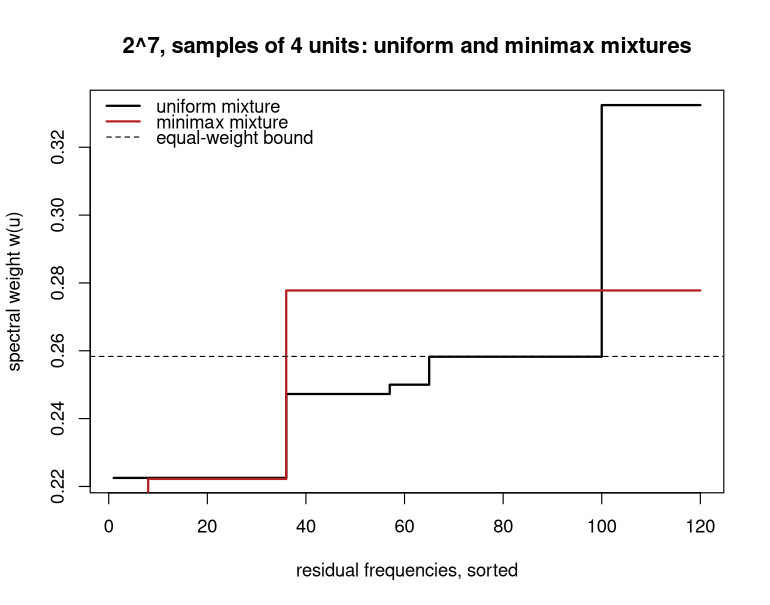

In [31]:
R27 <- !main_effect_set(f27, S1); R27[1] <- FALSE
plot(sort(spectral_weights(uni27)[R27]), type = "s", lwd = 2,
     xlab = "residual frequencies, sorted", ylab = "spectral weight w(u)",
     main = "2^7, samples of 4 units: uniform and minimax mixtures")
lines(sort(spectral_weights(mm$design)[R27]), type = "s", lwd = 2, col = "firebrick")
abline(h = (f27$N / 4 - 1) / sum(R27), lty = 2)
legend("topleft", c("uniform mixture", "minimax mixture", "equal-weight bound"),
       col = c("black", "firebrick", "black"), lty = c(1, 1, 2), lwd = c(2, 2, 1),
       bty = "n")

<a id="estimation"></a>
## 8. Variance estimation

With $r \ge 2$ cosets, `random_group_variance()` gives an unbiased estimator from the spread of the coset means, on
$r - 1$ degrees of freedom. `regression_variance()` fits the main-effects model on the sample. It has many more
degrees of freedom but is not unbiased in general. Both return a Student interval for the population mean.

In [32]:
set.seed(7)
s3 <- draw_sample(d61x3)
rg <- random_group_variance(s3, y, d61x3)
str(rg)
reg <- regression_variance(s3, y, g61, S4)
str(reg)
c(population_mean = mean(y), exact_variance = design_variance(d61x3, y))

List of 4
 $ estimate: num 138
 $ variance: num 0.00565
 $ df      : num 2
 $ interval: num [1:2] 137 138


List of 4
 $ estimate: num 138
 $ variance: num 0.00565
 $ df      : int 2
 $ interval: num [1:2] 137 138


population_mean  exact_variance 
    138.5229777       0.2775282 

On this grid sample, the main-effects model of rows, columns and both diagonals leaves only $r - 1 = 2$ residual
degrees of freedom. The two estimates therefore coincide. In the complete factorial frame $2^7$, balanced on its
seven variables, take two parallel flats of 8 units ($k = 16$). The random-group estimator then has $r - 1 = 1$
degree of freedom, and the regression estimator has 9 on this sample. The response has main effects, an
interaction and noise.

In [33]:
X27 <- f27$X - 1/2
set.seed(11)
y27 <- drop(X27 %*% rnorm(7)) + 3 * X27[, 1] * X27[, 2] + rnorm(f27$N, sd = 0.3)
d16 <- coset_design(f27, S1, h = 3, r = 2)
d16
s16 <- draw_sample(d16)
est <- list(random_groups = random_group_variance(s16, y27, d16),
            regression = regression_variance(s16, y27, f27, S1))
data.frame(estimate = sapply(est, `[[`, "estimate"),
           variance = sapply(est, `[[`, "variance"),
           df = sapply(est, `[[`, "df"),
           lower = sapply(est, function(e) e$interval[1]),
           upper = sapply(est, function(e) e$interval[2]))
c(population_mean = mean(y27), exact_variance = design_variance(d16, y27))

Coset design C(h = 3, nu, r = 2) on GF(2)^7: N = 128, sample size k = 16, 7 stratifications
nu: 4811 direction(s)

              estimate    variance     df lower        upper     
random_groups 0.009354591 3.924527e-07 1   0.001394656 0.01731453
regression    0.009354591 4.464318e-02 9  -0.468615055 0.48732424

population_mean  exact_variance 
    -0.01219949      0.03948272 

With one degree of freedom, the random-group estimate is very unstable. Here it is far below the exact
variance, while the regression estimate is close to it. Section S6 of the paper's supplement evaluates both
estimators over the whole support.

<a id="diagnostics"></a>
## 9. Evaluating any design

These functions take samples from any design with inclusion probabilities $k/N$, such as the cube method or
simple random sampling, and put them on the scale of the paper.

- `balance_check()` compares the stratum counts with proportional allocation.
- `main_effect_weight()` gives $t_M(s)$, which is zero exactly for balanced samples.
- `main_effect_share()` estimates the share $\tau$ of the weight left on the main-effect frequencies.
- `worst_case_bound()` estimates the lower bound on the worst-case variance, relative to an equal-weight design
  (Proposition 3).

In [34]:
# 2000 simple random samples of 61 units
srs <- replicate(2000, sample.int(g61$N, 61), simplify = FALSE)
# largest deviation from the target 61/61 = 1 unit per stratum
balance_check(g61, S4, srs[[1]])$max_deviation
balance_check(g61, S4, draw_sample(d61)$units)$max_deviation   # zero for a coset sample

         rows       columns antidiagonals     diagonals 
            3             4             3             2 

         rows       columns antidiagonals     diagonals 
            0             0             0             0 

In [35]:
# t_M(s) of the first simple random samples
round(head(main_effect_weight(g61, S4, srs, k = 61)), 4)
# zero, up to rounding, for an exactly balanced sample
round(main_effect_weight(g61, S4, draw_sample(d61)$units, k = 61), 12)

[1] 3.9016 4.0656 3.7705 3.7049 3.7377 4.1311

[1] 0

For simple random sampling, $\tau = d_{\mathcal S}/(N-1) = 240/3720 = 0.0645$, and the bound with $C = 1$ is
$1 + \tau\,(|R_{\mathcal S}|/d_{\mathcal S} - 1) = 1.871$. These are the values of Tables 3 and S5 of the paper.
An equal-weight design has bound 1.

In [36]:
main_effect_share(g61, S4, srs, k = 61)
worst_case_bound(g61, S4, srs, k = 61, C = 1)
coset_samples <- lapply(draw_sample(d61, n = 200), `[[`, "units")
worst_case_bound(g61, S4, coset_samples, k = 61, C = 1)

         tau           se 
0.0644584699 0.0001277789 

      bound          se 
1.870189344 0.001725015 

bound    se 
    1     0 

<a id="coverage"></a>
## 10. Coverage check

This cell reads the notebook file and checks that every function exported by the package is called in a code
cell above. The print methods `print.coset_frame()` and `print.coset_design()` are called by auto-printing in
Sections 1 and 5.

In [37]:
nb <- jsonlite::fromJSON("cosetsampling_functions.ipynb", simplifyVector = FALSE)
code_cells <- Filter(function(cl) cl$cell_type == "code", nb$cells)
src <- paste(unlist(lapply(code_cells, `[[`, "source")), collapse = "\n")
exports <- sort(getNamespaceExports("cosetsampling"))
called <- vapply(exports, function(fn)
  grepl(paste0("\\b", fn, "\\("), src, perl = TRUE), TRUE)
c(exported = length(exports), called = sum(called))
exports[!called]

exported   called 
      35       35 

character(0)

In [38]:
cat(R.version.string, "\n")
cat("cosetsampling", format(packageVersion("cosetsampling")),
    "| lpSolve", format(packageVersion("lpSolve")), "\n")
cat("executed", format(Sys.time(), "%Y-%m-%d %H:%M %Z"), "\n")

R version 4.3.3 (2024-02-29) 


cosetsampling 0.1.0 | lpSolve 5.6.23 


executed 2026-10-18 21:58 CEST 
